In [61]:
from transformers import Qwen2TokenizerFast, Qwen3ForCausalLM, AutoConfig
import torch
import time
import torch
from diffusers.schedulers import FlowMatchEulerDiscreteScheduler
from diffusers.models import AutoencoderKLFlux2, Flux2Transformer2DModel
import numpy as np
import random
from tqdm import tqdm
import json
import vaezip

import matplotlib.pyplot as plt
from stdev.utils.image_tools import *

device = "cuda"
plt.style.use("dark_background")

In [5]:
dtype = torch.bfloat16

text_encoder = Qwen3ForCausalLM.from_pretrained(
    "../models/FLUX.2-klein-4B/text_encoder", local_files_only=True
).to(device)
tokenizer = Qwen2TokenizerFast.from_pretrained(
    "../models/FLUX.2-klein-4B/tokenizer", local_files_only=True, device=device
)

scheduler = FlowMatchEulerDiscreteScheduler.from_pretrained(
    "../models/FLUX.2-klein-4B/scheduler", device=device
)
vae = AutoencoderKLFlux2.from_pretrained("../models/FLUX.2-klein-4B/vae", device=device).to(
    device, dtype
)
transformer = Flux2Transformer2DModel.from_pretrained(
    "../models/FLUX.2-klein-4B/transformer", device=device
).to(device, dtype)


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

The config attributes {'force_upcast': True} were passed to AutoencoderKLFlux2, but are not expected and will be ignored. Please verify your config.json configuration file.
There are modules in AutoencoderKLFlux2 that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in Flux2Transformer2DModel that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


In [6]:
def _get_qwen3_prompt_embeds(
    text_encoder: Qwen3ForCausalLM,
    tokenizer: Qwen2TokenizerFast,
    prompt: str | list[str],
    dtype: torch.dtype | None = None,
    device: torch.device | None = None,
    max_sequence_length: int = 512,
    hidden_states_layers: list[int] = (9, 18, 27),
):
    dtype = text_encoder.dtype if dtype is None else dtype
    device = text_encoder.device if device is None else device

    prompt = [prompt] if isinstance(prompt, str) else prompt

    all_input_ids = []
    all_attention_masks = []

    for single_prompt in prompt:
        messages = [{"role": "user", "content": single_prompt}]
        text = tokenizer.apply_chat_template(
            messages,
            tokenize=False,
            add_generation_prompt=True,
            enable_thinking=False,
        )
        inputs = tokenizer(
            text,
            return_tensors="pt",
            padding="max_length",
            truncation=True,
            max_length=max_sequence_length,
        )

        all_input_ids.append(inputs["input_ids"])
        all_attention_masks.append(inputs["attention_mask"])

    input_ids = torch.cat(all_input_ids, dim=0).to(device)
    attention_mask = torch.cat(all_attention_masks, dim=0).to(device)

    # Forward pass through the model
    output = text_encoder(
        input_ids=input_ids,
        attention_mask=attention_mask,
        output_hidden_states=True,
        use_cache=False,
    )

    # Only use outputs from intermediate layers and stack them
    out = torch.stack([output.hidden_states[k] for k in hidden_states_layers], dim=1)
    out = out.to(dtype=dtype, device=device)

    batch_size, num_channels, seq_len, hidden_dim = out.shape
    prompt_embeds = out.permute(0, 2, 1, 3).reshape(batch_size, seq_len, num_channels * hidden_dim)

    return prompt_embeds


def _prepare_text_ids(
    x: torch.Tensor,  # (B, L, D) or (L, D)
    t_coord: torch.Tensor | None = None,
):
    B, L, _ = x.shape
    out_ids = []

    for i in range(B):
        t = torch.arange(1) if t_coord is None else t_coord[i]
        h = torch.arange(1)
        w = torch.arange(1)
        l = torch.arange(L)

        coords = torch.cartesian_prod(t, h, w, l)
        out_ids.append(coords)

    return torch.stack(out_ids)


@torch.no_grad()
def encode_prompt(
    prompt: str | list[str],
    device: torch.device | None = None,
    num_images_per_prompt: int = 1,
    prompt_embeds: torch.Tensor | None = None,
    max_sequence_length: int = 512,
    text_encoder_out_layers: tuple[int] = (9, 18, 27),
):
    prompt = [prompt] if isinstance(prompt, str) else prompt

    prompt_embeds = _get_qwen3_prompt_embeds(
        text_encoder=text_encoder,
        tokenizer=tokenizer,
        prompt=prompt,
        device=device,
        max_sequence_length=max_sequence_length,
        hidden_states_layers=text_encoder_out_layers,
    )

    batch_size, seq_len, _ = prompt_embeds.shape
    prompt_embeds = prompt_embeds.repeat(1, num_images_per_prompt, 1)
    prompt_embeds = prompt_embeds.view(batch_size * num_images_per_prompt, seq_len, -1)

    text_ids = _prepare_text_ids(prompt_embeds)
    text_ids = text_ids.to(device)
    return prompt_embeds, text_ids

In [19]:
def _prepare_latent_ids(
    latents: torch.Tensor,  # (B, C, H, W)
):
    r"""
    Generates 4D position coordinates (T, H, W, L) for latent tensors.

    Args:
        latents (torch.Tensor):
            Latent tensor of shape (B, C, H, W)

    Returns:
        torch.Tensor:
            Position IDs tensor of shape (B, H*W, 4) All batches share the same coordinate structure: T=0,
            H=[0..H-1], W=[0..W-1], L=0
    """

    batch_size, _, height, width = latents.shape

    t = torch.arange(1)  # [0] - time dimension
    h = torch.arange(height)
    w = torch.arange(width)
    l = torch.arange(1)  # [0] - layer dimension

    # Create position IDs: (H*W, 4)
    latent_ids = torch.cartesian_prod(t, h, w, l)

    # Expand to batch: (B, H*W, 4)
    latent_ids = latent_ids.unsqueeze(0).expand(batch_size, -1, -1)

    return latent_ids


def _patchify_latents(latents):
    batch_size, num_channels_latents, height, width = latents.shape
    latents = latents.view(batch_size, num_channels_latents, height // 2, 2, width // 2, 2)
    latents = latents.permute(0, 1, 3, 5, 2, 4)
    latents = latents.reshape(batch_size, num_channels_latents * 4, height // 2, width // 2)
    return latents


def _unpatchify_latents(latents):
    batch_size, num_channels_latents, height, width = latents.shape
    latents = latents.reshape(batch_size, num_channels_latents // (2 * 2), 2, 2, height, width)
    latents = latents.permute(0, 1, 4, 2, 5, 3)
    latents = latents.reshape(batch_size, num_channels_latents // (2 * 2), height * 2, width * 2)
    return latents


def _pack_latents(latents):
    """
    pack latents: (batch_size, num_channels, height, width) -> (batch_size, height * width, num_channels)
    """

    batch_size, num_channels, height, width = latents.shape
    latents = latents.reshape(batch_size, num_channels, height * width).permute(0, 2, 1)

    return latents


def _unpack_latents_with_ids(
    x: torch.Tensor,
    x_ids: torch.Tensor,
    height: int | None = None,
    width: int | None = None,
) -> list[torch.Tensor]:
    """
    using position ids to scatter tokens into place
    """
    x_list = []
    for data, pos in zip(x, x_ids):
        _, ch = data.shape  # noqa: F841
        h_ids = pos[:, 1].to(torch.int64)
        w_ids = pos[:, 2].to(torch.int64)

        # Use provided height/width to avoid DtoH sync from torch.max().item()
        h = height if height is not None else torch.max(h_ids) + 1
        w = width if width is not None else torch.max(w_ids) + 1

        flat_ids = h_ids * w + w_ids

        out = torch.zeros((h * w, ch), device=data.device, dtype=data.dtype)
        out.scatter_(0, flat_ids.unsqueeze(1).expand(-1, ch), data)

        # reshape from (H * W, C) to (H, W, C) and permute to (C, H, W)

        out = out.view(h, w, ch).permute(2, 0, 1)
        x_list.append(out)

    return torch.stack(x_list, dim=0)


def prepare_latents(
    batch_size,
    num_latents_channels,
    height,
    width,
    dtype,
    device,
    generator: torch.Generator,
):
    # VAE applies 8x compression on images but we must also account for packing which requires
    # latent height and width to be divisible by 2.

    vae_scale_factor = 8
    height = 2 * (int(height) // (vae_scale_factor * 2))
    width = 2 * (int(width) // (vae_scale_factor * 2))

    shape = (batch_size, num_latents_channels * 4, height // 2, width // 2)

    latents = torch.randn(shape, generator=generator, device=device, dtype=dtype)

    latent_ids = _prepare_latent_ids(latents)
    latent_ids = latent_ids.to(device)

    latents = _pack_latents(latents)  # [B, C, H, W] -> [B, H*W, C]
    return latents, latent_ids


latents_bn_mean = vae.bn.running_mean.view(1, -1, 1, 1).to(device, dtype)
latents_bn_std = torch.sqrt(vae.bn.running_var.view(1, -1, 1, 1) + vae.config.batch_norm_eps).to(
    device, dtype
)


def norm_unpatchified_latents(latents):
    latents = _patchify_latents(latents)
    latents = latents - latents_bn_mean
    latents = latents / latents_bn_std
    latents = _unpatchify_latents(latents)

    return latents


def denorm_unpatchified_latents(latents):
    latents = _patchify_latents(latents)
    latents = latents * latents_bn_std
    latents = latents + latents_bn_mean
    latents = _unpatchify_latents(latents)

    return latents


def decode_denorm_latents(latents):
    with torch.no_grad():
        image = vae.decode(latents.to(torch.bfloat16), return_dict=False)[0]

    return image


def torch_image_show(image):
    image = image.add(1).div(2)
    image = image.float()
    image = image.squeeze(0).permute(1, 2, 0)
    image = image.clip(0, 1)
    image = image.cpu().numpy()

    plt.imshow(image)
    plt.show()


In [20]:
def retrieve_timesteps(
    scheduler,
    num_inference_steps: int,
    device: str | torch.device,
    sigmas: list[float],
    **kwargs,
):
    scheduler.set_timesteps(sigmas=sigmas, device=device, **kwargs)
    timesteps = scheduler.timesteps
    num_inference_steps = len(timesteps)

    return timesteps, num_inference_steps


def compute_empirical_mu(image_seq_len: int, num_steps: int) -> float:
    a1, b1 = 8.73809524e-05, 1.89833333
    a2, b2 = 0.00016927, 0.45666666

    if image_seq_len > 4300:
        mu = a2 * image_seq_len + b2
        return float(mu)

    m_200 = a2 * image_seq_len + b2
    m_10 = a1 * image_seq_len + b1

    a = (m_200 - m_10) / 190.0
    b = m_200 - 200.0 * a
    mu = a * num_steps + b

    return float(mu)

In [21]:
import os

folder = "../datasets/axis-v1_1k"
extensions = ".txt"

all_files = [
    os.path.join(root, file)
    for root, _, files in os.walk(folder)
    for file in files
    if file.endswith(extensions)
]

all_prompts = []

for file in all_files:
    with open(file, "r") as f:
        prompt = f.read()
        all_prompts.append(prompt)

print(all_prompts[0])

The image features a large, ornate, and intricately designed ceiling with a mix of white and brown tones. The ceiling is adorned with a series of arches and curves, creating a visually striking and unique architectural element. The lighting in the room is dim, which adds to the overall ambiance and atmosphere. The ceiling is made of a combination of stone and plaster, giving it a textured and aged appearance. The arches and curves are formed by the interplay of these materials, resulting in a complex and visually appealing design. The ceiling's anatomy showcases the craftsmanship and attention to detail that went into its creation, making it a foc


In [34]:
modifiers = [
    "Anime art, sharp edges, minimalism, digital art, flat textures.",
    "Detailed realism photo. Sharp 4K textures.",
    "Oil on canvas art. Brush strokes. Painting.",
]


def build_random_prompt():
    prompt = random.choice(modifiers)
    prompt += " " + random.choice(all_prompts)

    return prompt


build_random_prompt()


'Oil on canvas art. Brush strokes. Painting. The image captures a bustling city at night, with a bridge crossing over a busy street. The street is filled with traffic, including multiple cars and a truck, all moving in different directions. The vehicles are scattered throughout the scene, with some closer to the viewer and others further away.\n\nThe cityscape is illuminated by streetlights, creating a vibrant atmosphere. The lights are positioned at various angles and heights, casting a warm glow over the urban landscape. The combination of the moving vehicles, the bridge, and the streetlights creates a dynamic and lively urban environment.'

In [52]:
SINGLE_BLOCK_INDEX = 15


@torch.no_grad()
def generate_one_block():

    num_inference_steps = 4

    prompt = build_random_prompt()
    seed = random.randint(0, 10000000)

    prompt_embeds, text_ids = encode_prompt(
        prompt=prompt,
        device=device,
        num_images_per_prompt=1,
        max_sequence_length=512,
        text_encoder_out_layers=(9, 18, 27),
    )

    generator = torch.Generator(device="cuda").manual_seed(seed)

    height = 1024
    width = 1024

    latents, latent_ids = prepare_latents(
        batch_size=1,
        num_latents_channels=32,
        height=height,
        width=width,
        dtype=dtype,
        device=device,
        generator=generator,
    )

    sigmas = np.linspace(1.0, 1 / num_inference_steps, num_inference_steps)

    image_seq_len = latents.shape[1]

    mu = compute_empirical_mu(image_seq_len=image_seq_len, num_steps=num_inference_steps)

    timesteps, num_inference_steps = retrieve_timesteps(
        scheduler,
        num_inference_steps,
        device,
        sigmas=sigmas,
        mu=mu,
    )

    scheduler.set_begin_index(0)

    init_latents = latents.clone()
    init_latents = _unpack_latents_with_ids(init_latents, latent_ids)
    init_latents = _unpatchify_latents(init_latents)

    # init_latents -> return

    captured_activations = {}

    def capture_hook(module, module_inputs, module_output):
        captured_activations["hidden_states"] = module_output

    hook_handle = transformer.single_transformer_blocks[SINGLE_BLOCK_INDEX].register_forward_hook(
        capture_hook
    )

    try:
        for i, t in enumerate(timesteps):
            timestep = t.expand(latents.shape[0]).to(latents.dtype)

            latent_model_input = latents.to(transformer.dtype)
            latent_image_ids = latent_ids

            noise_pred = transformer(
                hidden_states=latent_model_input,  # (B, image_seq_len, C)
                timestep=timestep / 1000,
                guidance=None,
                encoder_hidden_states=prompt_embeds,
                txt_ids=text_ids,  # B, text_seq_len, 4
                img_ids=latent_image_ids,  # B, image_seq_len, 4
                return_dict=False,
            )[0]

            noise_pred = noise_pred[:, : latents.size(1), :]

            # compute the previous noisy sample x_t -> x_t-1
            latents = scheduler.step(noise_pred, t, latents, return_dict=False)[0]
    finally:
        hook_handle.remove()

    # hidden activations of the last forward pass: drop text tokens, tokens -> spatial grid
    num_text_tokens = prompt_embeds.shape[1]
    block_activations = captured_activations["hidden_states"][:, num_text_tokens:, :]
    batch_size, _, inner_dim = block_activations.shape
    activations_grid = block_activations.permute(0, 2, 1).reshape(
        batch_size, inner_dim, height // 16, width // 16
    )  # [B, C, H/16, W/16]

    # decode

    vae_scale_factor = 8

    latent_height = 2 * (int(height) // (vae_scale_factor * 2))
    latent_width = 2 * (int(width) // (vae_scale_factor * 2))

    latents = _unpack_latents_with_ids(latents, latent_ids, latent_height // 2, latent_width // 2)

    latents_orig = _unpatchify_latents(latents)

    # latents_orig -> return

    latents = latents * latents_bn_std + latents_bn_mean
    latents = _unpatchify_latents(latents)

    image = decode_denorm_latents(latents)

    # downscale

    image_div_2 = torch.nn.functional.interpolate(
        image, size=(height // 2, width // 2), mode="bilinear", align_corners=False
    )

    # encode
    latents_div_2 = vae.encode(image_div_2).latent_dist.mean

    latents_div_2 = norm_unpatchified_latents(latents_div_2)

    # latents_div_2 -> return

    return init_latents, latents_orig, latents_div_2, prompt, activations_grid


torch.Size([1, 32, 128, 128]) tensor(-0.0007, device='cuda:0', dtype=torch.bfloat16) tensor(1., device='cuda:0', dtype=torch.bfloat16)
torch.Size([1, 32, 128, 128]) tensor(0.0291, device='cuda:0', dtype=torch.bfloat16) tensor(1., device='cuda:0', dtype=torch.bfloat16)
torch.Size([1, 32, 64, 64]) tensor(0.0391, device='cuda:0', dtype=torch.bfloat16) tensor(0.9766, device='cuda:0', dtype=torch.bfloat16)
torch.Size([1, 3072, 64, 64]) tensor(0.1279, device='cuda:0', dtype=torch.bfloat16) tensor(15.1250, device='cuda:0', dtype=torch.bfloat16)


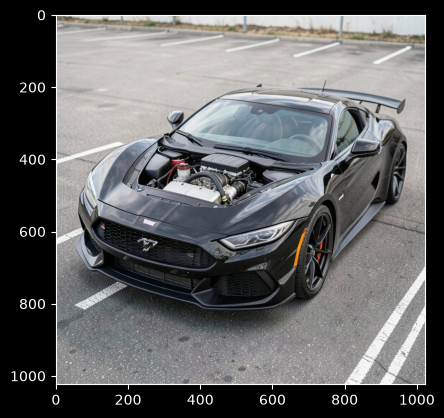

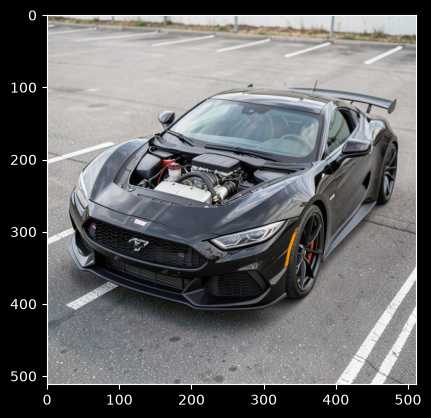

Detailed realism photo. Sharp 4K textures. The image features a sleek black sports car parked in a parking lot. The car is positioned in the foreground, occupying a significant portion of the frame. The car's tires are prominently visible, with one tire on the left side and another on the right side of the car. The car's hood is also visible, giving a clear view of the engine and its components. The car's design and features, such as the spoiler and the engine, are highlighted in the image, showcasing the car's performance capabilities. The parking lot setting provides a contrasting backdrop, emphasizing the car's striking appearance.


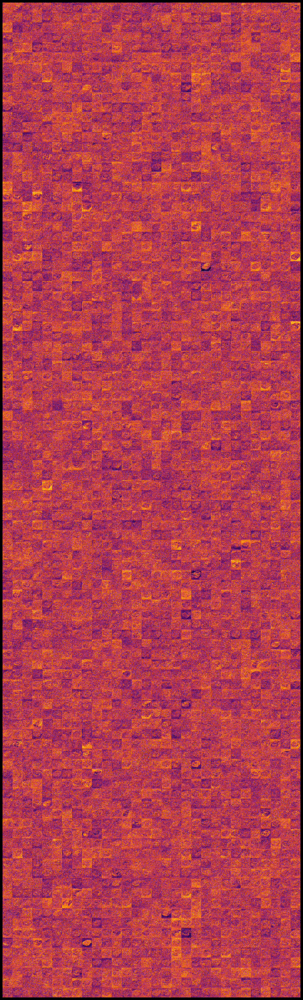

In [70]:
init_latents, latents_orig, latents_div_2, prompt, activations_grid = generate_one_block()
print(init_latents.shape, init_latents.mean(), init_latents.std())
print(latents_orig.shape, latents_orig.mean(), latents_orig.std())
print(latents_div_2.shape, latents_div_2.mean(), latents_div_2.std())
print(activations_grid.shape, activations_grid.mean(), activations_grid.std())

torch_image_show(decode_denorm_latents(denorm_unpatchified_latents(latents_orig)))
torch_image_show(decode_denorm_latents(denorm_unpatchified_latents(latents_div_2)))

print(prompt)


def show_channel_grid(
    activations: torch.Tensor, num_rows: int = 100, num_columns: int = 30
) -> None:
    """
    args:
        activations: [1, C, H, W], dtype: any float
    """
    channels = activations[0, : num_rows * num_columns].float()
    channel_min = channels.amin(dim=(1, 2), keepdim=True)
    channel_max = channels.amax(dim=(1, 2), keepdim=True)
    channels = (channels - channel_min) / (channel_max - channel_min + 1e-6)

    num_channels, height, width = channels.shape
    grid = channels.reshape(num_rows, num_columns, height, width)
    grid = grid.permute(0, 2, 1, 3).reshape(
        num_rows * height, num_columns * width
    )  # [rows*H, cols*W]

    plt.figure(figsize=(num_columns * 0.4, num_rows * 0.4))
    plt.imshow(grid.cpu().numpy(), cmap="inferno", interpolation="nearest")
    plt.axis("off")
    plt.tight_layout()
    plt.show()


show_channel_grid(activations_grid)

vaezip.save(
    {
        "init_latents": vaezip.encode(init_latents, codec="lbrq_8bit"),
        "latents_orig": vaezip.encode(latents_orig, codec="lbrq_8bit"),
        "latents_div_2": vaezip.encode(latents_div_2, codec="lbrq_8bit"),
        "activations_grid": vaezip.encode(activations_grid, codec="lbrq_4bit"),
    },
    path="samples/block.vz.safetensors",
)
